In [ ]:
from constraint import *

# Constraint Satisfaction Problems
## Map Colouring Example

We will use the python-constraint package. To install it open terminal prompt from Anaconda (if you use terminal: `conda install -c conda-forge python-constraint`), and type `pip install python-constraint`. To import see above i.e. `from constraint import *`. [You can find more information about the python-constraint package here](https://labix.org/python-constraint).


The problem is described below. More information is available in slides.

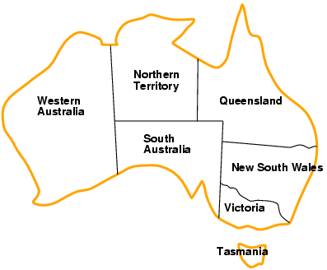

$$X=\{ WA, NT, Q, NSW, V, SA, T \} \\ D_{i}=\{ red, blue, green \} \\ C = \{ SA \neq WT, SA \neq NT, SA \neq Q, SA \neq NSW, SA \neq V, WA \neq NT, NT \neq Q, Q \neq NSW, NSW \neq V\}$$

Firstly create a `Problem` object. 

In [ ]:
p = Problem()


We can add variables one by one using `addVariable` method as shown below. The first argument is the name of the variable, and the second argument is its domain. 

In [ ]:
domain = ['red','blue','green']
p.addVariable("WA",domain)
p.addVariable("NT",domain)
p.addVariable("Q",domain)
p.addVariable("NSW",domain)
p.addVariable("V",domain)
p.addVariable("SA",domain)
p.addVariable("T",domain)

Alternatively, we can add the variables that share the same domain by `addVariables` domain as shown below.

In [ ]:
# p.addVariables(['WA','NT','Q','NSW','V','SA','T'],['red','blue','green'])

We need to add constraints. The first argument is the relation and the seciond argument is the scope of the constraint.

In [ ]:
p.addConstraint(lambda x,y : x != y, ('SA','WA'))
p.addConstraint(lambda x,y : x != y, ('SA','NT'))
p.addConstraint(lambda x,y : x != y, ('SA','Q'))
p.addConstraint(lambda x,y : x != y, ('SA','NSW'))
p.addConstraint(lambda x,y : x != y, ('SA','V'))
p.addConstraint(lambda x,y : x != y, ('WA','NT'))
p.addConstraint(lambda x,y : x != y, ('NT','Q'))
p.addConstraint(lambda x,y : x != y, ('Q','NSW'))
p.addConstraint(lambda x,y : x != y, ('NSW','V'))

You can get a single solution by `getSolution()` and all solutions by `getSolutions()` method of the problem object.

In [ ]:
p.getSolution()

## Sudoku Example
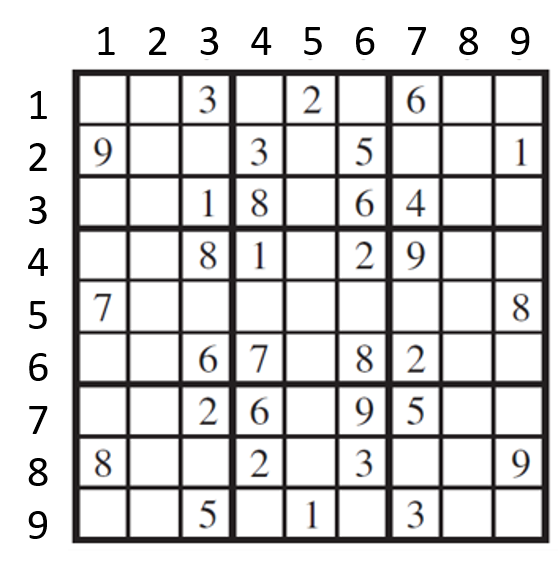

In Sudoku a variable represents a number entered to an associated cell. The domain of each variable is a digit between 1 and 9. All numbers in a row, in a column and 9 3X3 boxes in the board must be different. CSP formulation is as follows:
$$ X = \{ 11, 12, ..., 19, 21, 22, ..., 29, ... 99 \} $$
$$ D = \{1,2,3,4,5,6,7,8,9\}$$
$$ C = \{ Alldiff(11,12,13,14,15,16,17,18,19),\\
Alldiff(21,22,23,24,25,26,27,28,29),\\
...\\
Alldiff(11,21,31,41,51,61,71,81,91),\\
Alldiff(12,22,32,42,52,62,72,82,92),\\
...\\
Alldiff(11,12,13,21,22,23,31,32,33),\\
Alldiff(41,42,43,51,52,53,61,62,63,)\\
...\}$$

First we create a problem object and define the variables.

In [ ]:
p = Problem()
    
domain = [1,2,3,4,5,6,7,8,9]
for i in range(1,10):
    for j in range(1,10):
        p.addVariable(i*10 + j, domain)


Then we define the constraints for rows, columns and boxes.

In [ ]:

for i in range(1,10):
    rowConsindex = []
    colConsindex = []
    for j in range(1,10):
        rowConsindex.append(i*10 + j)
        colConsindex.append(j*10 + i)
    # Constraints for rows
    p.addConstraint(AllDifferentConstraint(), rowConsindex)
    # Constraints for columns
    p.addConstraint(AllDifferentConstraint(), colConsindex)

# Constraints for boxes
p.addConstraint(AllDifferentConstraint(), [11, 12, 13, 21, 22, 23, 31, 32 ,33])
p.addConstraint(AllDifferentConstraint(), [41, 42, 43, 51, 52, 53, 61, 62 ,63])
p.addConstraint(AllDifferentConstraint(), [71, 72, 73, 81, 82, 83, 91, 92 ,93])
p.addConstraint(AllDifferentConstraint(), [14, 15, 16, 24, 25, 26, 34, 35 ,36])
p.addConstraint(AllDifferentConstraint(), [44, 45, 46, 54, 55, 56, 64, 65 ,66])
p.addConstraint(AllDifferentConstraint(), [74, 75, 76, 84, 85, 86, 94, 95 ,96])
p.addConstraint(AllDifferentConstraint(), [17, 18, 19, 27, 28, 29, 37, 38 ,39])
p.addConstraint(AllDifferentConstraint(), [47, 48, 49, 57, 58, 59, 67, 68 ,69])
p.addConstraint(AllDifferentConstraint(), [77, 78, 79, 87, 88, 89, 97, 98 ,99])

We define the values given in the initial board as unary constraints

In [ ]:
# Initial Board
initValue = [
    [0, 0, 3, 0, 2, 0, 6, 0, 0],
    [9, 0, 0, 3, 0, 5, 0, 0, 1],
    [0, 0, 1, 8, 0, 6, 4, 0, 0],
    [0, 0, 8, 1, 0, 2, 9, 0, 0],
    [7, 0, 0, 0, 0, 0, 0, 0, 8],
    [0, 0, 6, 7, 0, 8, 2, 0, 0],
    [0, 0, 2, 6, 0, 9, 5, 0, 0],
    [8, 0, 0, 2, 0, 3, 0, 0, 9],
    [0, 0, 5, 0, 1, 0, 3, 0, 0],
]

# Unary Constraints for Initial Values
for i in range(1, 10):
    for j in range(1, 10):
        if initValue[i - 1][j - 1] != 0:
            p.addConstraint(
                lambda var, val = initValue[i-1][j-1]: var == val, (i * 10 + j,)
            )


We can get the solutions by `getSolutions()` method. Below a function for printing the solution in a format that is easy to interpret is given

In [ ]:
# Function to printing a readible solution
def printSol(solution):
    print('--------------------------')
    for i in range(1, 10):
        for j in range(1, 10):
            index = i * 10 + j
            print('',solution[index],'',end="")
        print("")
    print('---------------------------')


    
sol = p.getSolution()
printSol(sol)